In [19]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

RESULTS_FOLDER = Path("../../results/CNN_uci_results")
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)

ACTIVITIES = ["walking", "walking_upstairs", "walking_downstairs"]

# Load the windows made by build_features.py (as the CNN uses windows, not the features)
data = np.load("../../data/processed/uci/uci_windows.npz")
windows = data["windows"]
split = data["split"]
activity = data["activity"]

In [20]:
# Split into train and test using the "split" labels
is_train = split == "train"
X_train, X_test = windows[is_train], windows[~is_train]

# Converting the activity labels to numbers so keras can use them (walking = 0, walking_upstairs = 1 etc)
activity_to_number = {name: number for number, name in enumerate(ACTIVITIES)}
y_train = np.array([activity_to_number[a] for a in activity[is_train]])
y_test = np.array([activity_to_number[a] for a in activity[~is_train]])

# Scale each of the 9 signals to mean 0, standard deviation 1, learned from the TRAINING data only
mean = X_train.mean(axis=(0, 1))
std = X_train.std(axis=(0, 1))
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print(f"Train: {X_train.shape}   Test: {X_test.shape}")

Train: (3285, 128, 9)   Test: (1387, 128, 9)


In [21]:
model = models.Sequential()
model.add(layers.Input(shape=(128, 9)))
model.add(layers.Conv1D(32, 3, activation="relu", padding="same"))
model.add(layers.BatchNormalization())
model.add(layers.Conv1D(32, 3, activation="relu", padding="same"))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling1D(2))
model.add(layers.Dropout(0.2))                                         # randomly ignores 20%, reduces overfitting
model.add(layers.Conv1D(64, 3, activation="relu", padding="same"))
model.add(layers.BatchNormalization())
model.add(layers.Conv1D(64, 3, activation="relu", padding="same"))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling1D(2))
model.add(layers.Dropout(0.3))
model.add(layers.Flatten())
model.add(layers.Dense(64, activation="relu"))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(3))

model.compile(optimizer="adam",
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])

In [22]:
# Train the CNN for the 15 passes (testing each pass on the 20% of the training data which isnt learnt from)
history = model.fit(X_train, y_train, epochs=15, batch_size=64,
                    validation_split=0.2, verbose=2)

Epoch 1/15
42/42 - 5s - 129ms/step - accuracy: 0.6918 - loss: 0.9119 - val_accuracy: 0.6134 - val_loss: 0.8081
Epoch 2/15
42/42 - 1s - 32ms/step - accuracy: 0.9418 - loss: 0.1779 - val_accuracy: 0.6180 - val_loss: 1.0249
Epoch 3/15
42/42 - 1s - 30ms/step - accuracy: 0.9798 - loss: 0.0585 - val_accuracy: 0.6393 - val_loss: 1.0551
Epoch 4/15
42/42 - 1s - 31ms/step - accuracy: 0.9893 - loss: 0.0265 - val_accuracy: 0.6925 - val_loss: 0.7906
Epoch 5/15
42/42 - 1s - 30ms/step - accuracy: 0.9943 - loss: 0.0155 - val_accuracy: 0.8965 - val_loss: 0.2832
Epoch 6/15
42/42 - 1s - 31ms/step - accuracy: 0.9932 - loss: 0.0215 - val_accuracy: 0.9787 - val_loss: 0.0836
Epoch 7/15
42/42 - 1s - 31ms/step - accuracy: 0.9958 - loss: 0.0114 - val_accuracy: 0.9893 - val_loss: 0.0327
Epoch 8/15
42/42 - 1s - 30ms/step - accuracy: 0.9966 - loss: 0.0094 - val_accuracy: 0.9970 - val_loss: 0.0086
Epoch 9/15
42/42 - 2s - 37ms/step - accuracy: 0.9992 - loss: 0.0037 - val_accuracy: 0.9985 - val_loss: 0.0042
Epoch 10/

In [23]:
# The model outputs a score per activity; the highest score is its prediction (turns the labels back into names from 0-2)
predictions = np.array(ACTIVITIES)[model.predict(X_test, verbose=0).argmax(axis=1)]
y_test_names = np.array(ACTIVITIES)[y_test]

print("Model: Convolutional Neural Network")
print("Dataset: UCI")
print(f"Accuracy: {accuracy_score(y_test_names, predictions):.3f}")
print(f"Macro F1: {f1_score(y_test_names, predictions, average='macro'):.3f}\n")
print(classification_report(y_test_names, predictions, digits=3))

Model: Convolutional Neural Network
Dataset: UCI
Accuracy: 0.970
Macro F1: 0.969

                    precision    recall  f1-score   support

           walking      0.994     0.974     0.984       496
walking_downstairs      0.937     0.988     0.962       420
  walking_upstairs      0.976     0.949     0.962       471

          accuracy                          0.970      1387
         macro avg      0.969     0.970     0.969      1387
      weighted avg      0.970     0.970     0.970      1387



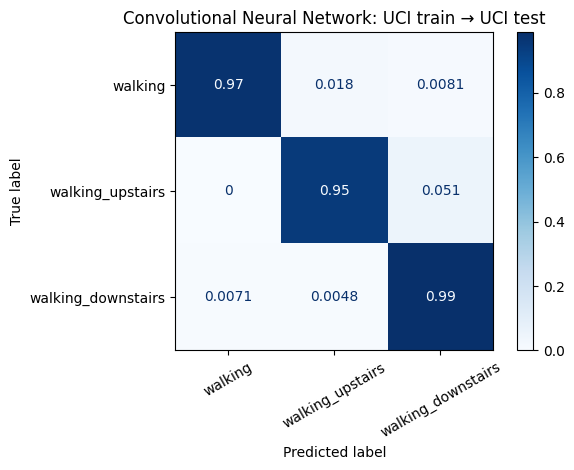

In [24]:
ConfusionMatrixDisplay.from_predictions(y_test_names, predictions, labels=ACTIVITIES, normalize="true",
                                        cmap="Blues", xticks_rotation=30)
plt.title("Convolutional Neural Network: UCI train → UCI test")
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "CNN_uci_confusion_matrix.png", dpi=150)
plt.show()

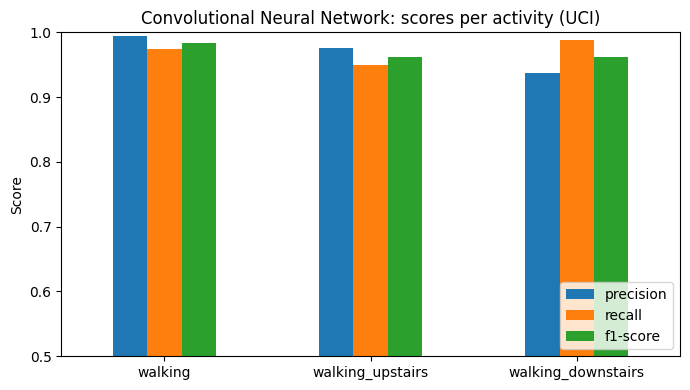

In [25]:
report = pd.DataFrame(classification_report(y_test_names, predictions, output_dict=True)).T
per_activity = report.loc[["walking", "walking_upstairs", "walking_downstairs"], ["precision", "recall", "f1-score"]]

per_activity.plot(kind="bar", figsize=(7, 4), ylim=(0.5, 1), rot=0)
plt.title("Convolutional Neural Network: scores per activity (UCI)")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "CNN_uci_per_activity.png", dpi=150)
plt.show()

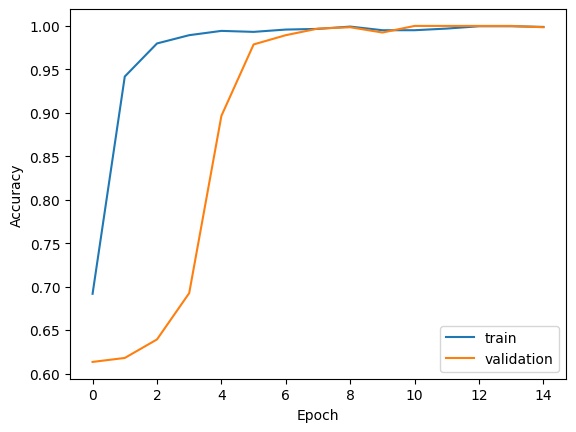

In [26]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.savefig(RESULTS_FOLDER / "CNN_training_curve.png", dpi=150)
plt.show()